# **Clustering** for Tabular Data - **GENERAL**


In [8]:
# Import libraries
import math
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as stats
import matplotlib.pyplot as plt
from pyexpat import features
from scipy.stats import pearsonr
import matplotlib.colors as mcolors

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler



In [2]:
# Loading Datasets
patients_df = pd.read_csv('../datasets/general_patients_TAB.csv')
icd10_category = pd.read_csv('../datasets/ICD10_category.csv')
list_silouhette = pd.read_csv('../datasets/list_Silouhette_Davies_Bouldin_TAB.csv')

In [63]:
patients_df.columns

Index(['study_id', 'subject_id', 'diagnosis', 'gender', 'age', 'dod',
       'age_range', 'diagnosis_categories', 'num_categories',
       'temperature_min', 'temperature_max', 'temperature_mean', 'o2sat_min',
       'o2sat_mean', 'mean_arterial_pressure_min',
       'mean_arterial_pressure_max', 'mean_arterial_pressure_mean',
       'RR_HR_ratio_min', 'RR_HR_ratio_max', 'RR_HR_ratio_mean',
       'temperature_class_mean', 'temperature_class_min',
       'temperature_class_max', 'o2sat_class_mean', 'o2sat_class_min',
       'mean_arterial_pressure_class_mean', 'mean_arterial_pressure_class_min',
       'mean_arterial_pressure_class_max', 'RR_HR_ratio_class_mean',
       'RR_HR_ratio_class_min', 'RR_HR_ratio_class_max', 'age_range_class'],
      dtype='object')

In [37]:
list_silouhette

,Normalization,Silhouette,Davies_Bouldin,Clusters,Cluster_Distribution,Features
0,StandardScaler,0.212739,1.713854,2,"{0: 19754, 1: 19723}","['age', 'num_categories', 'temperature_min', '..."
1,StandardScaler,0.191782,1.576377,3,"{2: 14669, 0: 12591, 1: 12217}","['age', 'num_categories', 'temperature_min', '..."
2,StandardScaler,0.203670,1.758033,2,"{0: 21105, 1: 18372}","['age', 'num_categories', 'temperature_min', '..."
3,StandardScaler,0.192016,1.616730,3,"{2: 14078, 0: 13014, 1: 12385}","['age', 'num_categories', 'temperature_min', '..."
4,StandardScaler,0.208342,1.737658,2,"{1: 20505, 0: 18972}","['age', 'num_categories', 'temperature_min', '..."
...,...,...,...,...,...,...
967,MinMaxScaler,0.240226,1.367029,3,"{2: 14884, 1: 14381, 0: 10212}","['age', 'num_categories', 'temperature_mean', ..."
968,MinMaxScaler,0.316066,1.198186,2,"{1: 22706, 0: 16771}","['age', 'num_categories', 'temperature_mean', ..."
969,MinMaxScaler,0.233212,1.407981,3,"{1: 14830, 2: 13507, 0: 11140}","['age', 'num_categories', 'temperature_mean', ..."
970,MinMaxScaler,0.323118,1.174509,2,"{1: 22789, 0: 16688}","['age', 'num_categories', 'temperature_mean', ..."


---
## Analisi e scelta del set di features per il clustering

#### Estrapolazione dei top 50 con Davies piu basso e top 50 con Silouhette piu alta


In [3]:
list_silouhette["Features"] = list_silouhette["Features"].apply(eval)

In [14]:
# Ordina il DataFrame per silhouette score decrescente
top_silouhette = list_silouhette.sort_values(by='Silhouette', ascending=False)

# Ordina il DataFrame per Davies-Bouldin Index crescente
top_davies = list_silouhette.sort_values(by='Davies_Bouldin', ascending=True)

d = 20  # Numero di risultati da selezionare

# Seleziona i primi d per ciascun criterio
top_X_silhouette = top_silouhette.head(d)
top_X_davies = top_davies.head(d)

# Mostra i risultati
print(f"Top {d} Silhouette:")
for _, row in top_X_silhouette.iterrows():
    print(f"Silhouette: {row['Silhouette']} | Davies: {row['Davies_Bouldin']} | Clusters: {row['Clusters']} | Features: {row['Features']}")

print(f"\nTop {d} Davies-Bouldin:")
for _, row in top_X_davies.iterrows():
    print(f"Silhouette: {row['Silhouette']} | Davies: {row['Davies_Bouldin']} | Clusters: {row['Clusters']} | Features: {row['Features']}")


Top 20 Silhouette:
Silhouette: 0.380272064355412 | Davies: 0.9891257822674538 | Clusters: 2 | Features: ['age', 'temperature_mean', 'o2sat_mean', 'mean_arterial_pressure_mean', 'RR_HR_ratio_mean']
Silhouette: 0.379726240219349 | Davies: 0.9911332181244108 | Clusters: 2 | Features: ['age', 'temperature_mean', 'o2sat_mean', 'mean_arterial_pressure_mean', 'RR_HR_ratio_min']
Silhouette: 0.3779307646021168 | Davies: 0.9955723258759684 | Clusters: 2 | Features: ['age', 'temperature_min', 'o2sat_mean', 'mean_arterial_pressure_mean', 'RR_HR_ratio_mean']
Silhouette: 0.376993814340093 | Davies: 0.9986202779616646 | Clusters: 2 | Features: ['age', 'temperature_min', 'o2sat_mean', 'mean_arterial_pressure_mean', 'RR_HR_ratio_min']
Silhouette: 0.3703917909251996 | Davies: 1.015865417757582 | Clusters: 2 | Features: ['age', 'temperature_max', 'o2sat_mean', 'mean_arterial_pressure_mean', 'RR_HR_ratio_mean']
Silhouette: 0.3696062093713372 | Davies: 1.0242508968769533 | Clusters: 2 | Features: ['age', '

Viene fatta l'intersezione dei top davies coi top silhouette per avere un meno set di features da analizzare e capire quale prendere

In [15]:
# Trova le features comuni presenti in entrambi i DataFrame
common_features_set = set(top_X_silhouette['Features'].apply(tuple)).intersection(set(top_X_davies['Features'].apply(tuple)))

# Filtra i DataFrame per ottenere le righe corrispondenti alle features comuni
common_features_df = top_X_silhouette[top_X_silhouette['Features'].apply(tuple).isin(common_features_set)].copy()

# Mostra il DataFrame delle features comuni
print("\nDataFrame delle Features Comuni:")
print(common_features_df)

# Mostra il conteggio delle features comuni
print(f"\nNumero di features comuni: {len(common_features_df)}")


DataFrame delle Features Comuni:
    Normalization  Silhouette  Davies_Bouldin  Clusters  Cluster_Distribution  \
754  MinMaxScaler    0.380272        0.989126         2  {1: 23275, 0: 16202}   
750  MinMaxScaler    0.379726        0.991133         2  {1: 23409, 0: 16068}   
682  MinMaxScaler    0.377931        0.995572         2  {1: 23413, 0: 16064}   
678  MinMaxScaler    0.376994        0.998620         2  {1: 23409, 0: 16068}   
718  MinMaxScaler    0.370392        1.015865         2  {1: 23409, 0: 16068}   
592  MinMaxScaler    0.369606        1.024251         2  {1: 22949, 0: 16528}   
714  MinMaxScaler    0.369572        1.018765         2  {1: 23369, 0: 16108}   
752  MinMaxScaler    0.369326        1.019537         2  {1: 23413, 0: 16064}   
588  MinMaxScaler    0.368766        1.027217         2  {1: 22888, 0: 16589}   
736  MinMaxScaler    0.367294        1.027263         2  {1: 23262, 0: 16215}   
508  MinMaxScaler    0.366799        1.033038         2  {1: 22696, 0: 1678

In [17]:
common_features_df

,Normalization,Silhouette,Davies_Bouldin,Clusters,Cluster_Distribution,Features
754,MinMaxScaler,0.380272,0.989126,2,"{1: 23275, 0: 16202}","[age, temperature_mean, o2sat_mean, mean_arter..."
750,MinMaxScaler,0.379726,0.991133,2,"{1: 23409, 0: 16068}","[age, temperature_mean, o2sat_mean, mean_arter..."
682,MinMaxScaler,0.377931,0.995572,2,"{1: 23413, 0: 16064}","[age, temperature_min, o2sat_mean, mean_arteri..."
678,MinMaxScaler,0.376994,0.998620,2,"{1: 23409, 0: 16068}","[age, temperature_min, o2sat_mean, mean_arteri..."
718,MinMaxScaler,0.370392,1.015865,2,"{1: 23409, 0: 16068}","[age, temperature_max, o2sat_mean, mean_arteri..."
592,MinMaxScaler,0.369606,1.024251,2,"{1: 22949, 0: 16528}","[age, num_categories, temperature_mean, o2sat_..."
714,MinMaxScaler,0.369572,1.018765,2,"{1: 23369, 0: 16108}","[age, temperature_max, o2sat_mean, mean_arteri..."
752,MinMaxScaler,0.369326,1.019537,2,"{1: 23413, 0: 16064}","[age, temperature_mean, o2sat_mean, mean_arter..."
588,MinMaxScaler,0.368766,1.027217,2,"{1: 22888, 0: 16589}","[age, num_categories, temperature_mean, o2sat_..."
736,MinMaxScaler,0.367294,1.027263,2,"{1: 23262, 0: 16215}","[age, temperature_mean, o2sat_min, mean_arteri..."


#### Crea i scatter plot PCA dei 19 estrapolati

In [52]:
patients_df.columns

Index(['study_id', 'subject_id', 'diagnosis', 'gender', 'age', 'dod',
       'age_range', 'diagnosis_categories', 'num_categories',
       'temperature_min', 'temperature_max', 'temperature_mean', 'o2sat_min',
       'o2sat_mean', 'mean_arterial_pressure_min',
       'mean_arterial_pressure_max', 'mean_arterial_pressure_mean',
       'RR_HR_ratio_min', 'RR_HR_ratio_max', 'RR_HR_ratio_mean',
       'temperature_class_mean', 'temperature_class_min',
       'temperature_class_max', 'o2sat_class_mean', 'o2sat_class_min',
       'mean_arterial_pressure_class_mean', 'mean_arterial_pressure_class_min',
       'mean_arterial_pressure_class_max', 'RR_HR_ratio_class_mean',
       'RR_HR_ratio_class_min', 'RR_HR_ratio_class_max', 'age_range_class'],
      dtype='object')

C:\Users\ironl\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
C:\Users\ironl\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
C:\Users\ironl\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
C:\Users\ironl\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
C:\Users\ironl\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
C:\Us

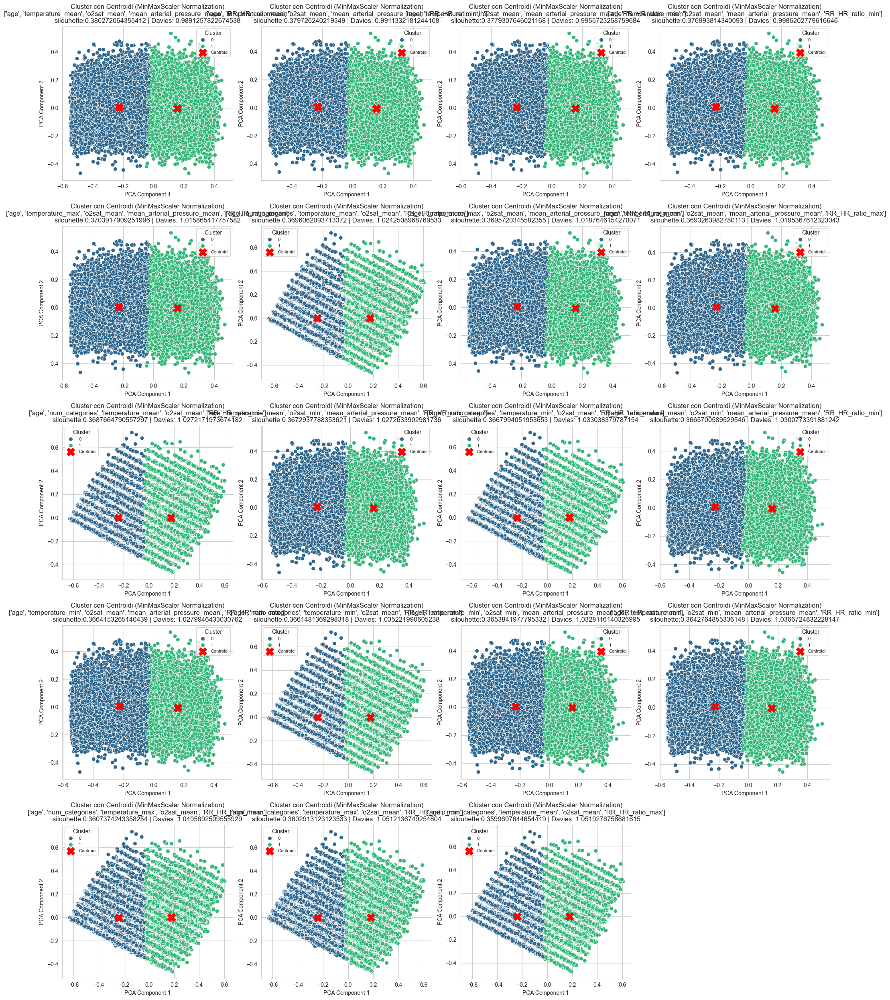

In [16]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Scegli il valore ottimale di K
n_clusters = 2  # Cambia con il valore ottimale trovato

# Numero di grafici per riga
n_cols = 4
n_rows = -(-len(common_features_df.iloc[:]) // n_cols)  # Calcola il numero di righe necessarie

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows))
axes = axes.flatten()  # Appiattisci gli assi per iterare facilmente

# Itera sui primi 10 set di features dalla tabella sorted_df
for idx, row in enumerate(common_features_df.iloc[:].itertuples(index=False)):
    features = row.Features
    normalization_method = row.Normalization

    # Scegli il metodo di normalizzazione
    if normalization_method == 'MinMaxScaler':
        scaler = MinMaxScaler()
    elif normalization_method == 'StandardScaler':
        scaler = StandardScaler()
    else:
        raise ValueError(f"Metodo di normalizzazione non valido: {normalization_method}")

    # Normalizza i dati
    normalized_patients_df = pd.DataFrame(scaler.fit_transform(patients_df[features]), columns=features)

    # Esegui il clustering con KMeans
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(normalized_patients_df)

    # Riduci i dati a 2 dimensioni con PCA
    pca = PCA(n_components=2)
    data_2d = pca.fit_transform(normalized_patients_df)

    # Riduci i centroidi dei cluster a 2 dimensioni con PCA
    centroids_2d = pca.transform(kmeans.cluster_centers_)

    # Aggiungi i risultati PCA ai dati
    pca_df = pd.DataFrame(data_2d, columns=['PCA1', 'PCA2'])
    pca_df['cluster'] = kmeans.labels_

    # Visualizza cluster e centroidi
    ax = axes[idx]
    sns.scatterplot(ax=ax, data=pca_df, x='PCA1', y='PCA2', hue='cluster', palette='viridis', s=50)
    ax.scatter(centroids_2d[:, 0], centroids_2d[:, 1], s=200, c='red', marker='X', label='Centroidi')
    ax.set_title(
        f'Cluster con Centroidi ({normalization_method} Normalization)\n{features}\nsilouhette:{row.Silhouette} | Davies: {row.Davies_Bouldin}')
    ax.set_xlabel('PCA Component 1')
    ax.set_ylabel('PCA Component 2')
    ax.legend(title='Cluster', fontsize=8)

# Rimuovi eventuali assi vuoti
for i in range(len(common_features_df.iloc[:]), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()


---
### Set di features scelto :

In [78]:
features = ['age', 'temperature_mean', 'o2sat_mean', 'mean_arterial_pressure_mean', 'RR_HR_ratio_mean']

---
---
## Applicazione **KMEANS** su unico set di features

---
### Procedo con la normalizzazione migliore per il mio set di dati: Min Max normalization

In [13]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler

features = ['age', 'temperature_mean', 'o2sat_mean', 'mean_arterial_pressure_mean', 'RR_HR_ratio_mean']
patients_df = pd.read_csv("../datasets/general_patients_TAB.csv")
# Normalizzazione Min-Max
scaler_minmax = MinMaxScaler()
normalized_df = scaler_minmax.fit_transform(patients_df[features])


In [14]:
# Scegli il valore ottimale di K (ad esempio, 3)
from sklearn. cluster._kmeans import KMeans
n_clusters = 2
kmeans = KMeans(n_clusters=n_clusters, random_state=42) #  random_state=42
kmeans.fit(normalized_df)

# Aggiungi i cluster come nuova colonna al DataFrame originale
patients_df['cluster'] = kmeans.labels_



Centroidi dei Cluster:
         age  temperature_mean  o2sat_mean  mean_arterial_pressure_mean  \
0  43.458061         98.238831   98.316244                    93.219762   
1  74.834847         98.156038   97.508225                    91.588089   

   RR_HR_ratio_mean  
0          0.214915  
1          0.231139  

Distribuzione nei Cluster:
               age  temperature_mean  o2sat_mean  mean_arterial_pressure_mean  \
cluster                                                                         
0        43.423219         98.238734   98.317393                    93.220511   
1        74.810569         98.156233   97.508675                    91.590092   

         RR_HR_ratio_mean  
cluster                    
0                0.214891  
1                0.231130  


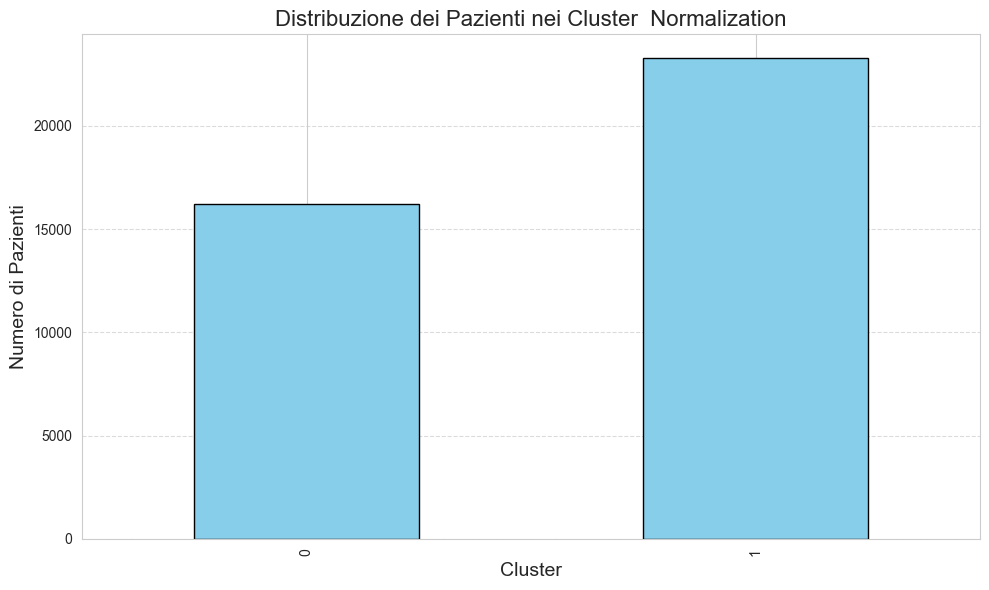

In [15]:
from sklearn.decomposition import PCA

centroids = pd.DataFrame(scaler_minmax.inverse_transform(kmeans.cluster_centers_), columns=features)
print(f"Centroidi dei Cluster:")
print(centroids)

# Analisi della distribuzione nei cluster
print(f"\nDistribuzione nei Cluster:")
cluster_distribution = patients_df.groupby(f'cluster')[features].mean()
print(cluster_distribution)

# Visualizzazione dei cluster
plt.figure(figsize=(10, 6))
patients_df[f'cluster'].value_counts().sort_index().plot(kind='bar', color='skyblue', edgecolor='black')
plt.title(f'Distribuzione dei Pazienti nei Cluster  Normalization', fontsize=16)
plt.xlabel('Cluster', fontsize=14)
plt.ylabel('Numero di Pazienti', fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show() # {1: 777, 0: 310}

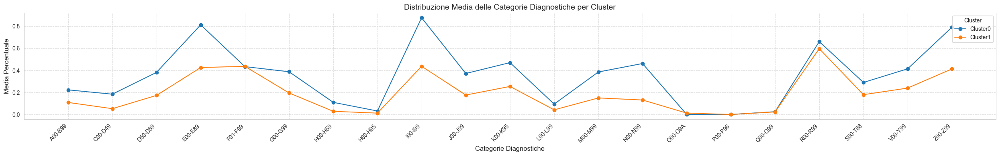

In [25]:
import matplotlib.pyplot as plt
import pandas as pd

# Assicurati che le categorie diagnostiche siano interpretate correttamente
patients_df['diagnosis_categories'] = patients_df['diagnosis_categories'].apply(
    lambda x: eval(x) if isinstance(x, str) else x)

# Lista delle categorie diagnostiche
cat = [
    'A00-B99', 'C00-D49', 'D50-D89', 'E00-E89', 'F01-F99', 'G00-G99', 'H00-H59', 'H60-H95',
    'I00-I99', 'J00-J99', 'K00-K95', 'L00-L99', 'M00-M99', 'N00-N99', 'O00-O9A', 'P00-P96',
    'Q00-Q99', 'R00-R99', 'S00-T88', 'V00-Y99', 'Z00-Z99'
]
# Calcola le medie per ogni categoria per cluster
centers = []
for cluster in patients_df['cluster'].unique():
    cluster_data = patients_df[patients_df['cluster'] == cluster]
    cluster_means = []
    for category in cat:
        # Calcola la percentuale di pazienti con quella categoria diagnostica
        cluster_means.append(
            cluster_data['diagnosis_categories'].apply(lambda x: category in x).mean()
        )
    centers.append(cluster_means)

# Genera il grafico
plt.figure(figsize=(25, 4))
for i in range(len(centers)):
    plt.plot(centers[i], marker='o', label=f'Cluster{i}')

# Configura gli assi
plt.xticks(range(len(cat)), cat, fontsize=10, rotation=45, ha='right')
plt.xlabel("Categorie Diagnostiche", fontsize=12)
plt.ylabel("Media Percentuale", fontsize=12)
plt.legend(fontsize=10, title="Cluster")
plt.grid(True, linestyle='--', alpha=0.6)

# Mostra il grafico
plt.title("Distribuzione Media delle Categorie Diagnostiche per Cluster", fontsize=14)
plt.tight_layout()
plt.show()


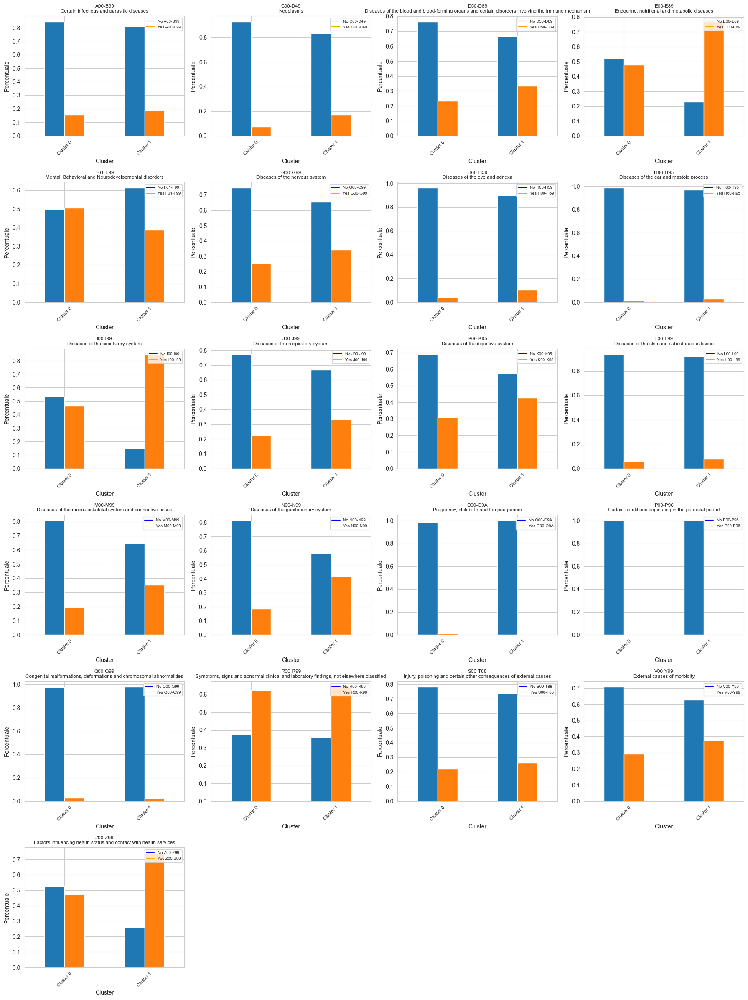

In [20]:
import matplotlib.pyplot as plt
import pandas as pd

# Carica il file delle categorie diagnostiche
icd10_category = pd.read_csv('../datasets/icd10_category.csv')

# Converti le categorie diagnostiche in formato lista, se necessario
patients_df['diagnosis_categories'] = patients_df['diagnosis_categories'].apply(
    lambda x: eval(x) if isinstance(x, str) else x
)

# Funzione per verificare la presenza di una categoria diagnostica e generare il grafico
def verify_diagnosis_category(category, ax):
    # Crea una colonna che indica se un paziente ha quella categoria
    patients_df[f'has_{category}'] = patients_df['diagnosis_categories'].apply(lambda x: category in x)

    # Crea una tabella di contingenza normalizzata per calcolare la percentuale per cluster
    diagnosis_categories_xt_pct = pd.crosstab(
        patients_df['cluster'],  # Cluster
        patients_df[f'has_{category}'],  # Presenza della categoria
        normalize='index'  # Percentuali per ogni cluster
    )

    # Assicurati che la tabella contenga sempre le colonne 'No' e 'Yes'
    diagnosis_categories_xt_pct.columns = [f'No {category}', f'Yes {category}']

    # Traccia il grafico a barre
    diagnosis_categories_xt_pct.plot(kind='bar', stacked=False, ax=ax, legend=False)
    ax.set_title(f'{category}\n{icd10_category[icd10_category["Code_range"] == category]["Description"].iloc[0]}',
                 fontsize=8.5)
    ax.set_xlabel('Cluster')
    ax.set_ylabel('Percentuale')
    ax.set_xticks(range(len(diagnosis_categories_xt_pct)))
    ax.set_xticklabels([f'Cluster {i}' for i in diagnosis_categories_xt_pct.index], rotation=45, fontsize=8)

    # Aggiungi legenda manuale
    handles = [
        plt.Line2D([0], [0], color='blue', label=f'No {category}'),
        plt.Line2D([0], [0], color='orange', label=f'Yes {category}')
    ]
    ax.legend(handles=handles, fontsize=7, loc='upper right')

# Lista delle categorie diagnostiche
cat = [
    'A00-B99', 'C00-D49', 'D50-D89', 'E00-E89', 'F01-F99', 'G00-G99', 'H00-H59', 'H60-H95',
    'I00-I99', 'J00-J99', 'K00-K95', 'L00-L99', 'M00-M99', 'N00-N99', 'O00-O9A', 'P00-P96',
    'Q00-Q99', 'R00-R99', 'S00-T88', 'V00-Y99', 'Z00-Z99'
]

# Configura il layout del grafico
n_cols = 4
n_rows = -(-len(cat) // n_cols)  # Calcola il numero di righe necessarie
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))

# Genera i grafici per ogni categoria diagnostica
for idx, category in enumerate(cat):
    row, col = divmod(idx, n_cols)
    ax = axes[row, col] if n_rows > 1 else axes[col]
    verify_diagnosis_category(category, ax)

# Rimuovi assi vuoti nel layout
for idx in range(len(cat), n_rows * n_cols):
    row, col = divmod(idx, n_cols)
    fig.delaxes(axes[row, col])

# Mostra il layout ottimizzato
plt.tight_layout()
plt.show()


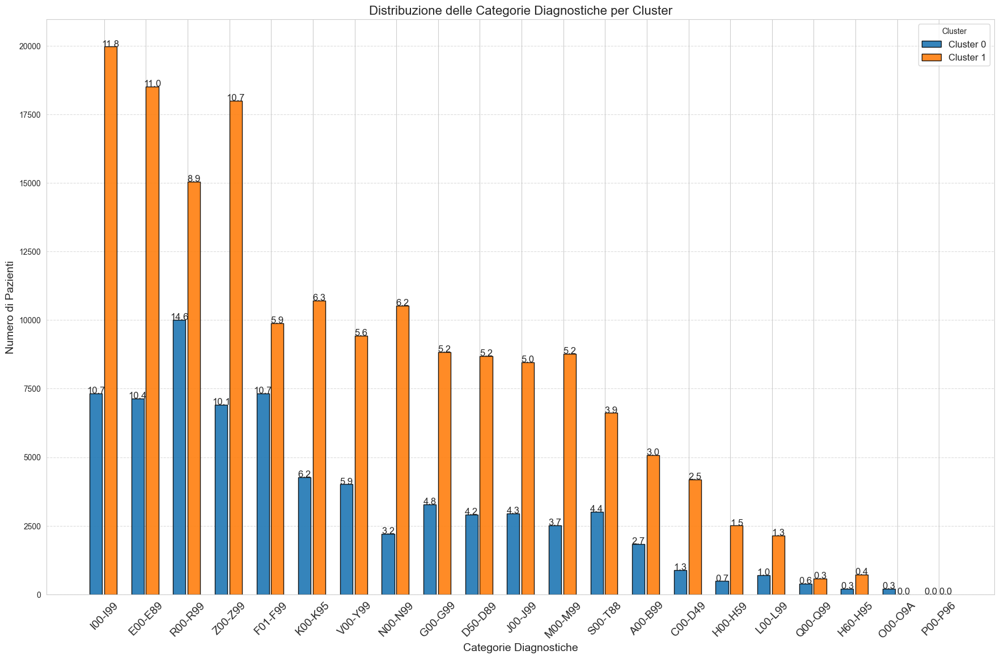

In [27]:
patients_df['diagnosis_categories'] = patients_df['diagnosis_categories'].apply(
    lambda x: eval(x) if isinstance(x, str) else x)

patients_expanded = patients_df.explode('diagnosis_categories')
cluster_groups = patients_expanded.groupby(['cluster', 'diagnosis_categories']).size().unstack(fill_value=0)
category_totals = cluster_groups.sum(axis=0).sort_values(ascending=False)
cluster_groups = cluster_groups[category_totals.index]
cluster_totals = cluster_groups.sum(axis=1)

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

plt.figure(figsize=(18, 12))

x = np.arange(len(cluster_groups.columns))
bar_width = 0.3
for i, cluster in enumerate(cluster_groups.index):
    values = cluster_groups.loc[cluster]
    percentages = (values / cluster_totals[cluster]) * 100
    positions = x + i * (bar_width + 0.05)
    plt.bar(positions, values, width=bar_width, label=f'Cluster {cluster}', color=colors[i % len(colors)],
            edgecolor='black', alpha=0.9)
    for pos, val, pct in zip(positions, values, percentages):
        if val > 0:
            plt.text(pos, val + 5, f'{pct:.1f}', ha='center', fontsize=12)

plt.xticks(x + ((bar_width + 0.1) * (len(cluster_groups.index) - 1)) / 2, cluster_groups.columns, rotation=45,
           fontsize=14)
plt.xlabel("Categorie Diagnostiche", fontsize=14)
plt.ylabel("Numero di Pazienti", fontsize=14)
plt.title("Distribuzione delle Categorie Diagnostiche per Cluster", fontsize=16)
plt.legend(fontsize=12, title="Cluster")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout(pad=2)
plt.show()


In [78]:
# Funzione per calcolare il range di età
intervallo = 20
def get_age_range(age):
    lower_bound = (age // intervallo) * intervallo  # Calcola il limite inferiore
    upper_bound = lower_bound + intervallo  # Calcola il limite superiore
    return f"{int(lower_bound)}-{int(upper_bound)}"

# Applicare la funzione alla colonna "age"
patients_df['age_range'] = patients_df['age'].apply(get_age_range)

# Visualizzare il risultato
print(patients_df[['age', 'age_range']].head())


    age age_range
0  52.0     40-60
1  57.0     40-60
2  86.0    80-100
3  75.0     60-80
4  64.0     60-80


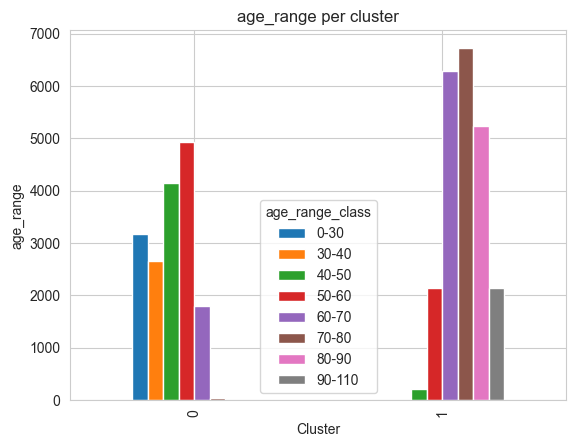

In [28]:
age_range_xt_pct = pd.crosstab(kmeans.labels_,patients_df['age_range_class'])
age_range_xt_pct
age_range_xt_pct.plot(kind='bar', stacked=False,
                      title='age_range per cluster')
plt.xlabel('Cluster')
plt.ylabel('age_range')
plt.show()

In [86]:
# Calcolo del numero di pazienti nel range di età 0-30 anni nei due cluster
# Filtra il dataset per considerare solo i pazienti nel range di età 0-30
patients_df_filtered = patients_df[(patients_df['age'] >= 0) & (patients_df['age'] <= 40)]

# Conta i pazienti in ciascun cluster
count_by_cluster = patients_df_filtered['cluster'].value_counts()

# Restituisce il conteggio per ogni cluster
count_by_cluster


cluster
0    5830
Name: count, dtype: int64

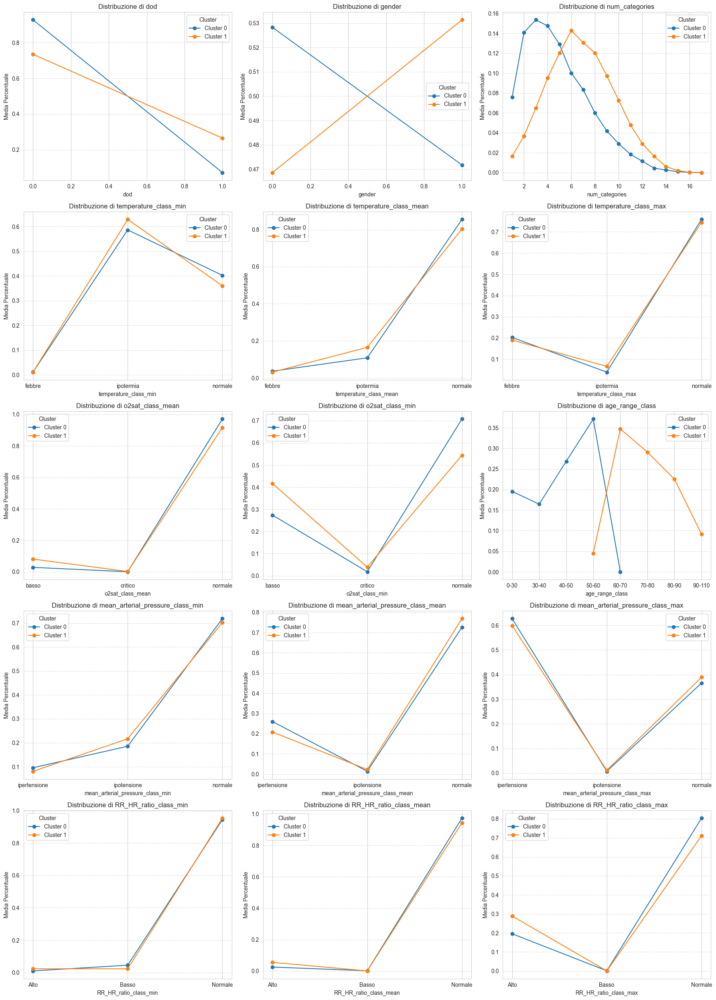

In [16]:
import matplotlib.pyplot as plt
import pandas as pd


# Funzione per generare i grafici a linee per la distribuzione media

def line_plot_view_clusters(cluster_attr, patients_df):
    # Attributi da analizzare
    attributes = ['dod', 'gender', 'num_categories',
                  'temperature_class_min', 'temperature_class_mean', 'temperature_class_max',
                  'o2sat_class_mean', 'o2sat_class_min',
                  'age_range_class', 'mean_arterial_pressure_class_min',
                  'mean_arterial_pressure_class_mean', 'mean_arterial_pressure_class_max',
                  'RR_HR_ratio_class_min', 'RR_HR_ratio_class_mean', 'RR_HR_ratio_class_max'
                  ]
    clusters = patients_df[cluster_attr].unique()
    n_cols = 3
    n_rows = -(-len(attributes) // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))

    for idx, attr in enumerate(attributes):
        row = idx // n_cols
        col = idx % n_cols
        ax = axes[row, col]

        # Calcola le medie per ogni cluster
        centers = []
        for cluster in clusters:
            cluster_data = patients_df[patients_df[cluster_attr] == cluster]
            cluster_means = cluster_data.groupby(attr).size() / len(cluster_data)
            centers.append(cluster_means)

        # Genera il grafico per ogni cluster
        for cluster_value, cluster_means in zip(clusters, centers):
            ax.plot(cluster_means.index, cluster_means.values, marker='o', label=f'Cluster {cluster_value}')


        ax.set_title(f'Distribuzione di {attr}', fontsize=12)
        ax.set_xlabel(attr, fontsize=10)
        ax.set_ylabel('Media Percentuale', fontsize=10)
        ax.grid(axis='y', linestyle='--', alpha=0.7)
        ax.legend(title='Cluster')

    for i in range(len(attributes), n_rows * n_cols):
        fig.delaxes(axes.flat[i])

    plt.tight_layout()
    plt.show()


# Esegui la funzione
line_plot_view_clusters('cluster', patients_df)


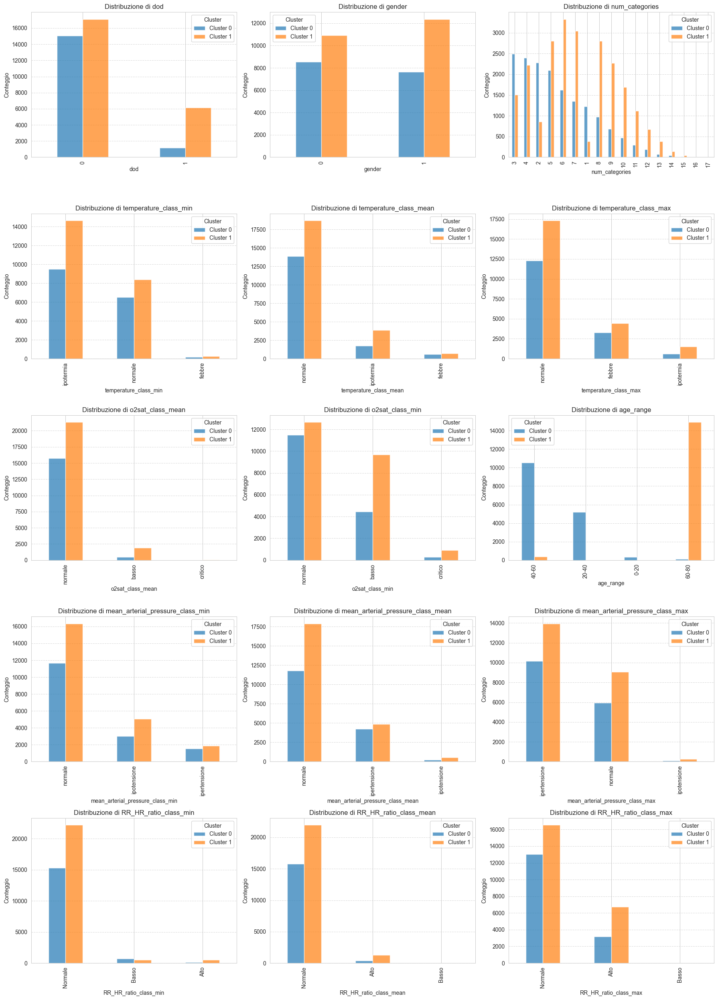

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

# Funzione per generare i grafici a istogramma per la distribuzione delle variabili
def istogram_view_clusters(cluster_attr, patients_df):
    # Attributi da analizzare
    attributes = [
        'dod', 'gender', 'num_categories',
        'temperature_class_min', 'temperature_class_mean', 'temperature_class_max',
        'o2sat_class_mean', 'o2sat_class_min',
        'age_range', 'mean_arterial_pressure_class_min',
        'mean_arterial_pressure_class_mean', 'mean_arterial_pressure_class_max',
        'RR_HR_ratio_class_min', 'RR_HR_ratio_class_mean', 'RR_HR_ratio_class_max'
    ]

    # Ottieni i valori unici dei cluster
    clusters = patients_df[cluster_attr].unique()

    # Configura il layout dei grafici
    n_cols = 3
    n_rows = -(-len(attributes) // n_cols)  # Calcolo del numero di righe necessario
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))

    for idx, attr in enumerate(attributes):
        row = idx // n_cols
        col = idx % n_cols
        ax = axes[row, col]

        # Crea un DataFrame vuoto per la distribuzione
        dist_df = pd.DataFrame()

        # Calcola la distribuzione per ogni cluster
        for cluster_value in clusters:
            cluster_data = patients_df[patients_df[cluster_attr] == cluster_value]
            cluster_counts = cluster_data[attr].value_counts()
            dist_df[f'Cluster {cluster_value}'] = cluster_counts

        # Riempie i valori mancanti con 0
        dist_df = dist_df.fillna(0)

        # Genera il grafico a istogramma
        dist_df.plot(kind='bar', ax=ax, alpha=0.7)
        ax.set_title(f'Distribuzione di {attr}', fontsize=12)
        ax.set_xlabel(attr, fontsize=10)
        ax.set_ylabel('Conteggio', fontsize=10)
        ax.grid(axis='y', linestyle='--', alpha=0.7)
        ax.legend(title='Cluster')

    # Rimuove eventuali assi vuoti
    for i in range(len(attributes), n_rows * n_cols):
        fig.delaxes(axes.flat[i])

    # Mostra i grafici
    plt.tight_layout()
    plt.show()

# Esegui la funzione
istogram_view_clusters('cluster', patients_df)


In [81]:
list(icd10_category['Code_range'])

['A00-B99',
 'C00-D49',
 'D50-D89',
 'E00-E89',
 'F01-F99',
 'G00-G99',
 'H00-H59',
 'H60-H95',
 'I00-I99',
 'J00-J99',
 'K00-K95',
 'L00-L99',
 'M00-M99',
 'N00-N99',
 'O00-O9A',
 'P00-P96',
 'Q00-Q99',
 'R00-R99',
 'S00-T88',
 'V00-Y99',
 'Z00-Z99']

---
## **Scatter Plot**

In [92]:
patients_df.columns

Index(['study_id', 'subject_id', 'diagnosis', 'gender', 'age', 'dod',
       'age_range', 'diagnosis_categories', 'num_categories',
       'temperature_min', 'temperature_max', 'temperature_mean', 'o2sat_min',
       'o2sat_mean', 'mean_arterial_pressure_min',
       'mean_arterial_pressure_max', 'mean_arterial_pressure_mean',
       'RR_HR_ratio_min', 'RR_HR_ratio_max', 'RR_HR_ratio_mean',
       'temperature_class_mean', 'temperature_class_min',
       'temperature_class_max', 'o2sat_class_mean', 'o2sat_class_min',
       'mean_arterial_pressure_class_mean', 'mean_arterial_pressure_class_min',
       'mean_arterial_pressure_class_max', 'RR_HR_ratio_class_mean',
       'RR_HR_ratio_class_min', 'RR_HR_ratio_class_max', 'age_range_class',
       'cluster', 'has_A00-B99', 'has_C00-D49', 'has_D50-D89', 'has_E00-E89',
       'has_F01-F99', 'has_G00-G99', 'has_H00-H59', 'has_H60-H95',
       'has_I00-I99', 'has_J00-J99', 'has_K00-K95', 'has_L00-L99',
       'has_M00-M99', 'has_N00-N99', 'ha

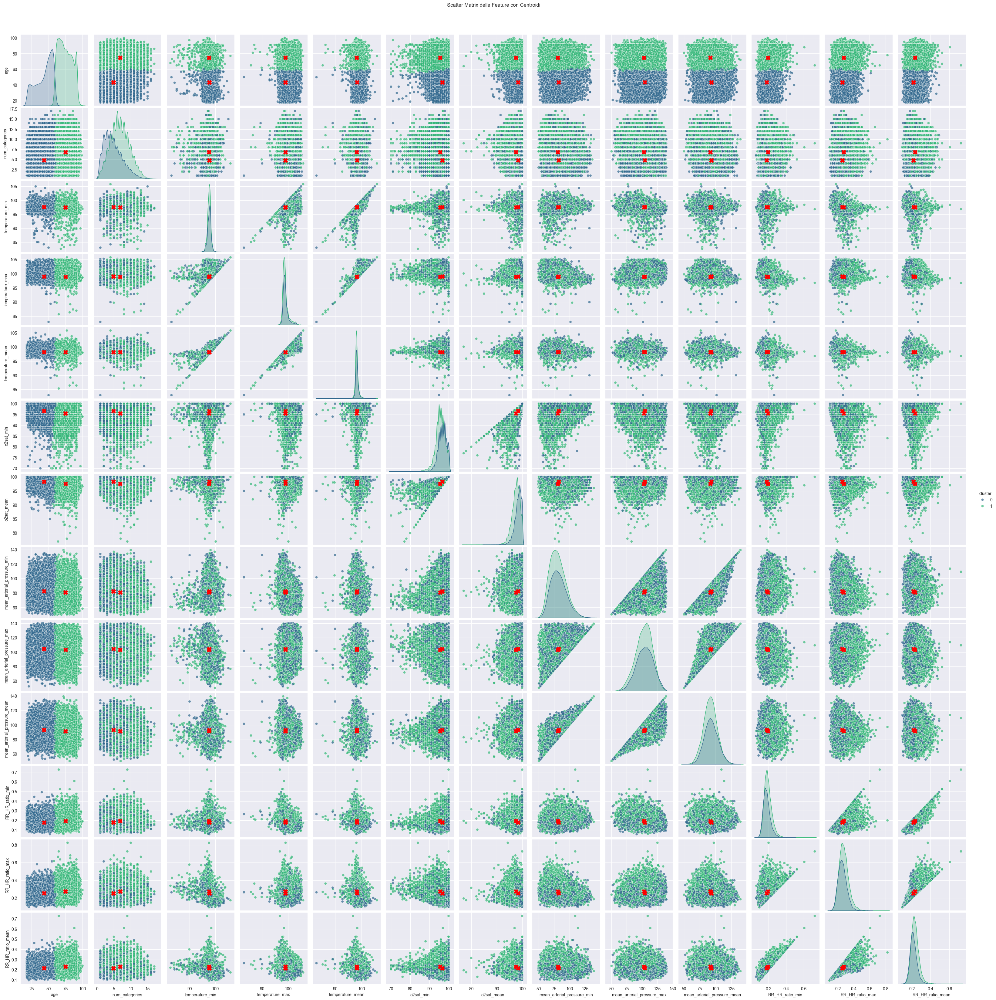

In [89]:
import seaborn as sns
f = ['age', 'num_categories',
     'temperature_min', 'temperature_max', 'temperature_mean', 'o2sat_min',
     'o2sat_mean', 'mean_arterial_pressure_min',
     'mean_arterial_pressure_max', 'mean_arterial_pressure_mean',
     'RR_HR_ratio_min', 'RR_HR_ratio_max', 'RR_HR_ratio_mean']
# Verifica e converte array/liste in valori scalari
for col in f + ['cluster']:
    if patients_df[col].apply(lambda x: isinstance(x, (list, np.ndarray))).any():
        patients_df[col] = patients_df[col].apply(lambda x: x[0] if isinstance(x, (list, np.ndarray)) else x)

# Converte le colonne in tipo numerico
for col in f:
    patients_df[col] = pd.to_numeric(patients_df[col], errors='coerce')

patients_df['cluster'] = pd.to_numeric(patients_df['cluster'], errors='coerce').astype('Int64')
subset = f + ['cluster']

# Rimuovi righe con NaN
features_df = patients_df.dropna(subset=subset)

# Calcola i centroidi per ogni cluster
centroids = features_df.groupby('cluster')[f].mean()

# Crea la scatter matrix
pairplot = sns.pairplot(features_df[subset], hue='cluster', palette='viridis', diag_kind='kde', plot_kws={'alpha': 0.7})


# Aggiungi i centroidi ai grafici
def add_centroids(ax, x_feature, y_feature):
    for cluster, centroid in centroids.iterrows():
        ax.scatter(
            centroid[x_feature], centroid[y_feature],
            color='red', marker='X', s=100, label=f'Centroid Cluster {cluster}' if cluster == 0 else ""
        )


# Itera su tutti i grafici e aggiungi i centroidi
for ax in pairplot.axes.flatten():
    if ax is not None:  # Assicurati che l'asse esista
        x_label = ax.get_xlabel()
        y_label = ax.get_ylabel()
        if x_label in f and y_label in f:
            add_centroids(ax, x_label, y_label)

# Mostra il grafico
plt.suptitle("Scatter Matrix delle Feature con Centroidi", y=1.02)
plt.show()


---

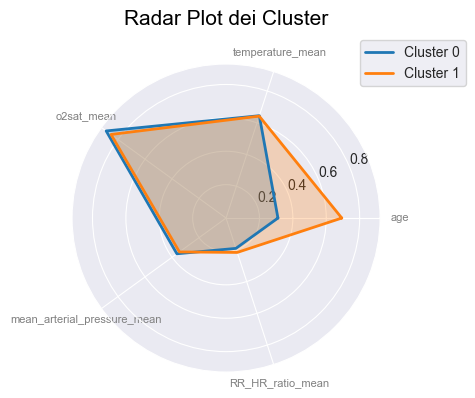

In [90]:
from math import pi
import matplotlib.pyplot as plt

# Features selezionate
# features = ['mean_temperature', 'mean_heartrate', 'std_temperature',
#             'std_heartrate', 'pulse_pressure', 'shock_index', 'mean_arterial_pressure',
#             'temperature_status']

# Centroidi dei cluster (assicurati che siano calcolati correttamente)
centers = kmeans.cluster_centers_  # Dimensioni: (n_clusters, n_features)

# Numero di variabili
N = len(features)

# Calcolo degli angoli
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]  # Chiude il cerchio

# Crea il radar plot
fig, ax = plt.subplots(figsize=(4, 4), subplot_kw={'projection': 'polar'})

# Per ogni cluster
for i in range(len(centers)):
    # Prendi i valori del cluster e chiudi il cerchio
    values = centers[i][:N].tolist()
    values += values[:1]

    # Disegna il radar plot
    ax.plot(angles, values, linewidth=2, linestyle='solid', label=f'Cluster {i}')
    ax.fill(angles, values, alpha=0.25)

# Aggiungi le etichette degli assi
plt.xticks(angles[:-1], features, color='grey', size=8)

# Aggiungi titolo e legenda
plt.title("Radar Plot dei Cluster", size=15, color='black', y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()


---
## **DBSCAN** 
### Studio dei parametri di clustering per DBSCAN
- eps: La distanza massima tra due punti affinché possano essere considerati parte dello stesso cluster.
- min_samples: Il numero minimo di punti richiesti per formare un cluster.

In [91]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# patients_df = pd.read_csv("merged_patients_shannon.csv")
# features = ['II', 'III', 'aVR', 'aVF', 'V5']
# Normalizzazione Min-Max
scaler_minmax = MinMaxScaler()
normalized_df = scaler_minmax.fit_transform(patients_df[features])
normalized_df

array([[0.41463415, 0.67397661, 0.85144928, 0.23283396, 0.16303411],
       [0.47560976, 0.65692008, 0.93236715, 0.4673325 , 0.16614179],
       [0.82926829, 0.66666667, 0.84782609, 0.47659176, 0.16128499],
       ...,
       [0.53658537, 0.63815789, 0.91304348, 0.4906367 , 0.16400478],
       [0.01219512, 0.66008772, 1.        , 0.3164794 , 0.32241312],
       [0.47560976, 0.66507177, 0.96837945, 0.58665305, 0.1900075 ]])

#### Calcolo del eps e min_sample

In [92]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.spatial.distance import pdist, squareform
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Gamma di valori per eps, min_samples
eps_values = [0.03, 0.05, 0.07, 0.09, 0.15, 0.25, 0.35, 0.60, 0.80, 1, 1.3, 1.6, 2]  # Aggiunti nuovi valori
min_samples_values = [3, 5, 7, 10, 15]

# Risultati finali
results = []

# Normalizza i dati
X = normalized_df

# Itera su eps e min_samples
for eps in eps_values:
    print(f"DBSCAN_eps_{eps}")
    for min_samples in min_samples_values:
        # Esegui DBSCAN
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(X)

        # Calcola il numero di cluster (escludendo il rumore)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_points = list(labels).count(-1)

        # Calcola la distribuzione dei punti nei cluster
        cluster_distribution = {}
        if n_clusters > 0:
            unique_labels, counts = np.unique(labels[labels != -1], return_counts=True)
            cluster_distribution = dict(zip(unique_labels, counts))

        # Calcola le metriche solo se ci sono almeno due cluster
        if n_clusters > 1:
            silhouette = silhouette_score(X, labels)
            davies_bouldin = davies_bouldin_score(X, labels)
            results.append({
                "eps": eps,
                "min_samples": min_samples,
                "clusters": n_clusters,
                "noise_points": noise_points,
                "silhouette": silhouette,
                "davies_bouldin": davies_bouldin,
                "cluster_distribution": cluster_distribution
            })
        else:
            silhouette = -1  # Valore predefinito se non ci sono cluster validi
            davies_bouldin = np.inf

        # Salva i risultati

        # print(f"kth_distances_eps_{eps}_min_samples_{min_samples}")

# Crea un DataFrame per analizzare i risultati
param_dbscan_df = pd.DataFrame(results)


DBSCAN_eps_0.03
DBSCAN_eps_0.05
DBSCAN_eps_0.07
DBSCAN_eps_0.09
DBSCAN_eps_0.15
DBSCAN_eps_0.25
DBSCAN_eps_0.35
DBSCAN_eps_0.6
DBSCAN_eps_0.8
DBSCAN_eps_1
DBSCAN_eps_1.3
DBSCAN_eps_1.6
DBSCAN_eps_2


In [95]:
param_dbscan_df

,eps,min_samples,clusters,noise_points,silhouette,davies_bouldin,cluster_distribution
0,0.03,3,544,10922,-0.703305,1.382552,"{0: 26304, 1: 7, 2: 4, 3: 3, 4: 4, 5: 5, 6: 18, 7: 4, 8: 5, 9: 3, 10: 5, 11: 3, 12: 5, 13: 4, 14: 12, 15: 4, 16: 5, 17: 3, 18: 4, 19: 12, 20: 6, 21: 4, 22: 3, 23: 3, 24: 5, 25: 5, 26: 8, 27: 4, 28: 3, 29: 16, 30: 4, 31: 3, 32: 11, 33: 3, 34: 3, 35: 9, 36: 4, 37: 8, 38: 3, 39: 3, 40: 15, 41: 3, 42: 13, 43: 4, 44: 3, 45: 3, 46: 15, 47: 16, 48: 3, 49: 3, 50: 3, 51: 5, 52: 4, 53: 3, 54: 5, 55: 3, 56: 3, 57: 3, 58: 3, 59: 4, 60: 4, 61: 8, 62: 6, 63: 3, 64: 8, 65: 4, 66: 4, 67: 4, 68: 3, 69: 9, 70: 3, 71: 4, 72: 4, 73: 5, 74: 3, 75: 3, 76: 3, 77: 4, 78: 10, 79: 4, 80: 6, 81: 6, 82: 5, 83: 5, 84: 3, 85: 3, 86: 4, 87: 10, 88: 6, 89: 16, 90: 4, 91: 6, 92: 9, 93: 6, 94: 6, 95: 4, 96: 4, 97: 5, 98: 3, 99: 6, ...}"
1,0.03,5,160,14851,-0.696779,1.488804,"{0: 23591, 1: 9, 2: 10, 3: 16, 4: 12, 5: 5, 6: 16, 7: 5, 8: 5, 9: 7, 10: 16, 11: 6, 12: 21, 13: 9, 14: 6, 15: 5, 16: 10, 17: 5, 18: 8, 19: 9, 20: 7, 21: 6, 22: 10, 23: 6, 24: 3, 25: 2, 26: 14, 27: 11, 28: 5, 29: 6, 30: 7, 31: 3, 32: 5, 33: 5, 34: 7, 35: 3, 36: 26, 37: 4, 38: 12, 39: 7, 40: 9, 41: 7, 42: 7, 43: 19, 44: 4, 45: 7, 46: 11, 47: 10, 48: 7, 49: 7, 50: 10, 51: 7, 52: 10, 53: 13, 54: 7, 55: 5, 56: 5, 57: 11, 58: 6, 59: 10, 60: 5, 61: 10, 62: 10, 63: 4, 64: 7, 65: 5, 66: 12, 67: 2, 68: 8, 69: 7, 70: 4, 71: 11, 72: 5, 73: 6, 74: 5, 75: 6, 76: 4, 77: 6, 78: 5, 79: 8, 80: 4, 81: 5, 82: 7, 83: 4, 84: 8, 85: 8, 86: 5, 87: 4, 88: 5, 89: 2, 90: 4, 91: 4, 92: 6, 93: 5, 94: 8, 95: 4, 96: 6, 97: 5, 98: 10, 99: 4, ...}"
2,0.03,7,90,17991,-0.676040,1.688993,"{0: 20805, 1: 10, 2: 11, 3: 13, 4: 10, 5: 14, 6: 7, 7: 12, 8: 6, 9: 11, 10: 9, 11: 5, 12: 7, 13: 9, 14: 16, 15: 8, 16: 6, 17: 12, 18: 10, 19: 4, 20: 13, 21: 7, 22: 6, 23: 11, 24: 6, 25: 9, 26: 7, 27: 10, 28: 23, 29: 7, 30: 9, 31: 5, 32: 6, 33: 8, 34: 5, 35: 6, 36: 11, 37: 8, 38: 10, 39: 7, 40: 6, 41: 7, 42: 6, 43: 6, 44: 7, 45: 7, 46: 10, 47: 11, 48: 9, 49: 8, 50: 5, 51: 12, 52: 8, 53: 7, 54: 5, 55: 3, 56: 7, 57: 7, 58: 7, 59: 5, 60: 5, 61: 7, 62: 7, 63: 4, 64: 6, 65: 7, 66: 6, 67: 5, 68: 5, 69: 7, 70: 6, 71: 7, 72: 9, 73: 6, 74: 5, 75: 7, 76: 6, 77: 7, 78: 5, 79: 7, 80: 8, 81: 7, 82: 7, 83: 5, 84: 7, 85: 6, 86: 4, 87: 4, 88: 7, 89: 5}"
3,0.03,10,51,22314,-0.668730,1.888659,"{0: 16680, 1: 8, 2: 18, 3: 13, 4: 18, 5: 14, 6: 8, 7: 14, 8: 10, 9: 5, 10: 18, 11: 8, 12: 9, 13: 12, 14: 8, 15: 13, 16: 18, 17: 9, 18: 11, 19: 8, 20: 7, 21: 7, 22: 8, 23: 6, 24: 8, 25: 7, 26: 14, 27: 11, 28: 9, 29: 8, 30: 10, 31: 7, 32: 9, 33: 10, 34: 10, 35: 6, 36: 8, 37: 6, 38: 10, 39: 6, 40: 10, 41: 10, 42: 10, 43: 9, 44: 8, 45: 10, 46: 5, 47: 10, 48: 6, 49: 9, 50: 7}"
4,0.03,15,32,28299,-0.625205,1.887182,"{0: 9964, 1: 662, 2: 17, 3: 14, 4: 53, 5: 29, 6: 14, 7: 12, 8: 13, 9: 57, 10: 9, 11: 15, 12: 27, 13: 14, 14: 15, 15: 16, 16: 57, 17: 21, 18: 13, 19: 14, 20: 7, 21: 24, 22: 10, 23: 8, 24: 14, 25: 7, 26: 10, 27: 10, 28: 12, 29: 17, 30: 12, 31: 11}"
5,0.05,3,53,2344,-0.520055,1.523274,"{0: 36931, 1: 5, 2: 5, 3: 4, 4: 4, 5: 4, 6: 7, 7: 3, 8: 3, 9: 5, 10: 3, 11: 3, 12: 4, 13: 6, 14: 4, 15: 3, 16: 4, 17: 4, 18: 7, 19: 4, 20: 5, 21: 3, 22: 3, 23: 4, 24: 4, 25: 3, 26: 3, 27: 9, 28: 3, 29: 6, 30: 5, 31: 5, 32: 3, 33: 3, 34: 3, 35: 3, 36: 3, 37: 3, 38: 4, 39: 3, 40: 3, 41: 3, 42: 3, 43: 5, 44: 3, 45: 4, 46: 3, 47: 3, 48: 3, 49: 3, 50: 3, 51: 3, 52: 3}"
6,0.05,5,16,2962,-0.438568,2.245834,"{0: 36449, 1: 3, 2: 4, 3: 4, 4: 5, 5: 7, 6: 4, 7: 3, 8: 3, 9: 5, 10: 5, 11: 5, 12: 5, 13: 4, 14: 5, 15: 4}"
7,0.05,7,7,3583,-0.289201,3.261567,"{0: 35867, 1: 4, 2: 6, 3: 3, 4: 5, 5: 3, 6: 6}"
8,0.05,10,2,4375,-0.013384,7.052500,"{0: 35092, 1: 10}"
9,0.07,3,17,695,-0.260490,1.719058,"{0: 38728, 1: 6, 2: 3, 3: 3, 4: 4, 5: 3, 6: 3, 7: 3, 8: 3, 9: 3, 10: 3, 11: 3, 12: 3, 13: 3, 14: 3, 15: 3, 16: 5}"


In [96]:
# Specifica il percorso del file CSV
output_file = "../datasets/param_dbscan_results_TAB.csv"

# Salva il DataFrame in un file CSV
param_dbscan_df.to_csv(output_file, index=False)

print(f"Risultati salvati in: {output_file}")


Risultati salvati in: ../datasets/param_dbscan_results_TAB.csv


---

---
# **Hierarchical**

In [18]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler

patients_df = pd.read_csv("../datasets/general_patients_TAB.csv")
features = ['age', 'temperature_mean', 'o2sat_mean', 'mean_arterial_pressure_mean', 'RR_HR_ratio_mean']
# Normalizzazione Min-Max
scaler_minmax = MinMaxScaler()
normalized_df = scaler_minmax.fit_transform(patients_df[features])
normalized_df

array([[0.41463415, 0.67397661, 0.85144928, 0.23283396, 0.16303411],
       [0.47560976, 0.65692008, 0.93236715, 0.4673325 , 0.16614179],
       [0.82926829, 0.66666667, 0.84782609, 0.47659176, 0.16128499],
       ...,
       [0.53658537, 0.63815789, 0.91304348, 0.4906367 , 0.16400478],
       [0.01219512, 0.66008772, 1.        , 0.3164794 , 0.32241312],
       [0.47560976, 0.66507177, 0.96837945, 0.58665305, 0.1900075 ]])

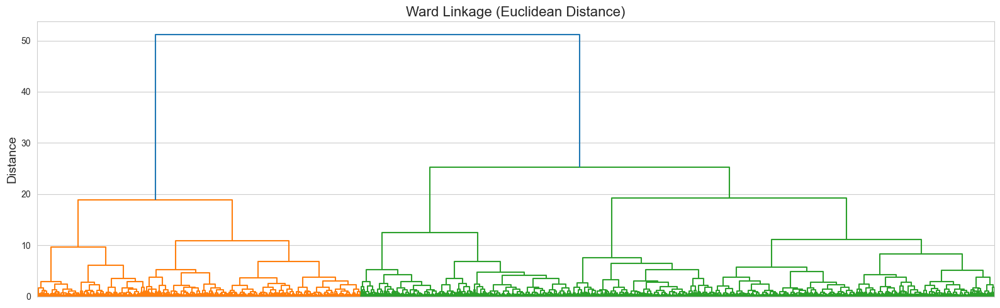

In [20]:
import os
import pandas as pd
import numpy as np
import scipy.cluster.hierarchy as sch
from scipy.spatial.distance import pdist
from matplotlib import pyplot as plt
import math

# Use patients_df as the dataset
data = patients_df

# Ensure that the selected features are numeric
for col in features:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Drop rows with missing values for the selected features
data = data.dropna(subset=features)

# Extract feature values for clustering
feature_values = normalized_df

# Distance Metrics and Linkage Methods
distance_metrics = ['euclidean']
linkage_methods = ['ward']

# Generate Dendrograms and calculate cluster distributions
results = []  # To store cluster distributions

# Create subplots based on the number of metrics and methods
fig, axes = plt.subplots(len(distance_metrics), len(linkage_methods), figsize=(16, len(distance_metrics) * 5))

# Ensure axes is always a list (even if there's only one plot)
if len(distance_metrics) * len(linkage_methods) == 1:
    axes = [axes]

# Loop through each combination of distance metric and linkage method
for plot_idx, (metric, method) in enumerate([(m, l) for m in distance_metrics for l in linkage_methods]):
    # Compute the distance matrix
    distance_matrix = pdist(feature_values, metric=metric)

    # Perform hierarchical clustering
    linkage_matrix = sch.linkage(distance_matrix, method=method)

    # Plot dendrogram
    ax = axes[plot_idx]
    sch.dendrogram(
        linkage_matrix,
        no_labels=True,
        ax=ax
    )
    ax.set_title(f"{method.capitalize()} Linkage ({metric.capitalize()} Distance)", fontsize=16)
    ax.set_xlabel("")
    ax.set_ylabel("Distance", fontsize=14)

# Adjust layout
plt.tight_layout()
plt.subplots_adjust(hspace=0.5, wspace=0.4)
plt.show()

# Create a DataFrame with cluster distributions
cluster_results_df = pd.DataFrame(results)


In [ ]:
import os
import pandas as pd
import numpy as np
import scipy.cluster.hierarchy as sch
from scipy.spatial.distance import pdist
from matplotlib import pyplot as plt
import math

data = patients_df

# Ensure that the selected features are numeric
for col in features:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Drop rows with missing values for the selected features
data = data.dropna(subset=features)

# Extract feature values for clustering
feature_values = normalized_df

# Distance Metrics and Linkage Methods
distance_metrics = ['euclidean']
linkage_methods = ['ward']
# 0.05, 0.1, 0.25, 0.5, 1, 1.5, 2, 3,
# Threshold for cutting the dendrogram (adjust as needed)
threshold = [4, 5, 7, 10, 15, 20]  # Heights for cutting the dendrogram

# Generate Dendrograms and calculate cluster distributions
results = []  # To store cluster distributions

fig, axes = plt.subplots(len(distance_metrics), len(linkage_methods), figsize=(16, len(distance_metrics) * 5))
axes = axes.flatten()

for tresh in threshold:
    print(f'tresh = {tresh}')
    for plot_idx, (metric, method) in enumerate([(m, l) for m in distance_metrics for l in linkage_methods]):
        # Compute the distance matrix
        distance_matrix = pdist(feature_values, metric=metric)

        # Perform hierarchical clustering
        linkage_matrix = sch.linkage(distance_matrix, method=method)

        # Assign clusters using fcluster
        clusters = sch.fcluster(linkage_matrix, t=tresh, criterion='distance')

        # Calculate the distribution of points in clusters
        cluster_counts = pd.Series(clusters).value_counts().to_dict()
        total_clusters = len(cluster_counts)  # Total number of clusters
        results.append({
            "Metric": metric,
            "Linkage": method,
            "Total_Clusters": total_clusters,
            "Threshold": tresh,
            "Cluster_Distribution": cluster_counts

        })



# Create a DataFrame with cluster distributions
cluster_results_df = pd.DataFrame(results)


In [ ]:
output_file = "../datasets/hierarchical_treshold_cluster_results_TAB.csv"
cluster_results_df.to_csv(output_file, index=False)
print(f"Risultati salvati in: {output_file}")

In [ ]:
# Filtra il DataFrame per distanza 'euclidean' e metodo di linkage 'complete'
euclidean_complete_df = cluster_results_df[
    (cluster_results_df['Metric'] == 'correlation') &
    (cluster_results_df['Linkage'] == 'ward')
    ]

# Visualizza il risultato
euclidean_complete_df

Verrranno estrapolati solo quelli col treshold giusto rispetto al dendogramma

In [ ]:
# Lista di condizioni specifiche
conditions = [
    {"Metric": "euclidean", "Linkage": "complete", "Threshold": 1.5},
    {"Metric": "euclidean", "Linkage": "ward", "Threshold": 4.5},
    {"Metric": "cosine", "Linkage": "complete", "Threshold": 0.60},
    {"Metric": "correlation", "Linkage": "average", "Threshold": 0.80},
    {"Metric": "correlation", "Linkage": "ward", "Threshold": 10}
]

# Filtra il DataFrame in base alle condizioni
filtered_dfs = []
for condition in conditions:
    filtered_dfs.append(cluster_results_df[
                            (cluster_results_df['Metric'] == condition['Metric']) &
                            (cluster_results_df['Linkage'] == condition['Linkage']) &
                            (cluster_results_df['Threshold'] == condition['Threshold'])
                            ])

# Combina tutti i risultati filtrati in un unico DataFrame
final_filtered_df = pd.concat(filtered_dfs, ignore_index=True)

# Mostra i risultati
final_filtered_df

# (Facoltativo) Salva il risultato in un file CSV
# final_filtered_df.to_csv("filtered_cluster_results.csv", index=False)


---
## Silhouette e Davies

In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.spatial.distance import pdist, squareform

# Inizializza una lista per i risultati
hierarchical_metrics = []

# Itera sul DataFrame filtrato
for index, row in final_filtered_df.iterrows():
    # Estrai i parametri dal DataFrame
    metric = row['Metric']
    linkage = row['Linkage']
    threshold = row['Threshold']
    n_clusters = row['Total_Clusters']
    # Filtra i dati delle features
    feature_values = normalized_df

    # Calcola la matrice delle distanze
    distance_matrix = pdist(feature_values, metric=metric)
    condensed_distance_matrix = squareform(distance_matrix)

    # Crea il linkage matrix per hierarchical clustering
    linkage_matrix = sch.linkage(distance_matrix, method=linkage)

    # Esegui il clustering con il threshold specificato
    clusters = sch.fcluster(linkage_matrix, t=threshold, criterion='distance')

    # Calcola le metriche se ci sono più di 1 cluster
    if len(set(clusters)) > 1:
        silhouette = silhouette_score(condensed_distance_matrix, clusters, metric='precomputed')
        davies_bouldin = davies_bouldin_score(feature_values, clusters)
    else:
        silhouette = -1  # Non applicabile
        davies_bouldin = float('inf')  # Non applicabile

    # Aggiungi i risultati
    hierarchical_metrics.append({
        "Metric": metric,
        "Linkage": linkage,
        "Threshold": threshold,
        "Total_Clusters": n_clusters,
        "Silhouette": silhouette,
        "Davies_Bouldin": davies_bouldin,
        "Cluster_Counts": dict(pd.Series(clusters).value_counts())
    })

# Crea un DataFrame con i risultati
hierarchical_metrics_df = pd.DataFrame(hierarchical_metrics)


---
### Analisi di clustering - HIERARCHICAL

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler

patients_df = pd.read_csv("../datasets/general_patients_TAB.csv.csv")
features = ['age', 'temperature_mean', 'o2sat_mean', 'mean_arterial_pressure_mean', 'RR_HR_ratio_mean']
# Normalizzazione Min-Max
scaler_minmax = MinMaxScaler()
normalized_df = scaler_minmax.fit_transform(patients_df[features])
normalized_df

In [ ]:
from scipy.spatial.distance import pdist
import scipy.cluster.hierarchy as sch
# Calcola la matrice delle distanze
distance_matrix = pdist(normalized_df, metric='euclidean')
# Costruisci il linkage matrix
linkage_matrix = sch.linkage(distance_matrix, method='ward')
# Plot del dendrogramma
plt.figure(figsize=(10, 6))
sch.dendrogram(linkage_matrix)
plt.title("Dendrogramma (Ward Linkage, Euclidean Distance)")
plt.xlabel("Samples")
plt.ylabel("Distance")
plt.show()



In [ ]:
from scipy.cluster.hierarchy import fcluster

# Taglia il dendrogramma per ottenere i cluster
threshold = 4.5  # Sostituisci con il valore identificato
clusters = fcluster(linkage_matrix, t=threshold, criterion='distance')

# Conta il numero di cluster
n_clusters = len(set(clusters))
print(f"Numero di cluster: {n_clusters}")

# Aggiungi i cluster ai dati originali
patients_df['cluster'] = clusters

# Analizza la distribuzione
cluster_distribution = patients_df['cluster'].value_counts()
print(cluster_distribution)


In [ ]:
from sklearn.decomposition import PCA
import seaborn as sns

# Riduci i dati a 2 dimensioni
pca = PCA(n_components=2)
pca_result = pca.fit_transform(normalized_df)

# Crea un DataFrame con i risultati della PCA e i cluster
pca_df = pd.DataFrame(pca_result, columns=['PCA1', 'PCA2'])
pca_df['cluster'] = clusters

# Visualizza i cluster
plt.figure(figsize=(10, 8))
sns.scatterplot(data=pca_df, x='PCA1', y='PCA2', hue='cluster', palette='viridis', s=50)
plt.title("Cluster (PCA)")
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Assicurati che le categorie diagnostiche siano interpretate correttamente
patients_df['diagnosis_categories'] = patients_df['diagnosis_categories'].apply(
    lambda x: eval(x) if isinstance(x, str) else x)

# Lista delle categorie diagnostiche
cat = [
    'A00-B99', 'C00-D49', 'D50-D89', 'E00-E89', 'F01-F99', 'G00-G99', 'H00-H59', 'H60-H95',
    'I00-I99', 'J00-J99', 'K00-K95', 'L00-L99', 'M00-M99', 'N00-N99', 'O00-O9A', 'P00-P96',
    'Q00-Q99', 'R00-R99', 'S00-T88', 'V00-Y99', 'Z00-Z99'
]
# Calcola le medie per ogni categoria per cluster
centers = []
for cluster in patients_df['cluster'].unique():
    cluster_data = patients_df[patients_df['cluster'] == cluster]
    cluster_means = []
    for category in cat:
        # Calcola la percentuale di pazienti con quella categoria diagnostica
        cluster_means.append(
            cluster_data['diagnosis_categories'].apply(lambda x: category in x).mean()
        )
    centers.append(cluster_means)

# Genera il grafico
plt.figure(figsize=(25, 4))
for i in range(len(centers)):
    plt.plot(centers[i], marker='o', label=f'Cluster{i}')

# Configura gli assi
plt.xticks(range(len(cat)), cat, fontsize=10, rotation=45, ha='right')
plt.xlabel("Categorie Diagnostiche", fontsize=12)
plt.ylabel("Media Percentuale", fontsize=12)
plt.legend(fontsize=10, title="Cluster")
plt.grid(True, linestyle='--', alpha=0.6)

# Mostra il grafico
plt.title("Distribuzione Media delle Categorie Diagnostiche per Cluster", fontsize=14)
plt.tight_layout()
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

icd10_category = pd.read_csv('../datasets/icd10_category.csv')
# Converti le categorie diagnostiche se necessario
patients_df['diagnosis_categories'] = patients_df['diagnosis_categories'].apply(
    lambda x: eval(x) if isinstance(x, str) else x)


def verify_diagnosis_category(category, ax):
    # Aggiungi colonna per indicare la presenza della categoria
    patients_df[f'has_{category}'] = patients_df['diagnosis_categories'].apply(lambda x: category in x)

    # Crea tabella di contingenza normalizzata
    diagnosis_categories_xt_pct = pd.crosstab(
        kmeans.labels_,  # Cluster
        patients_df[f'has_{category}'],  # Presenza della categoria
        normalize='index'  # Calcola le percentuali per ogni cluster
    )

    # Assicurati che ci siano sempre colonne per 'No' e 'Yes'
    expected_columns = [f'No {category}', f'Yes {category}']
    diagnosis_categories_xt_pct = diagnosis_categories_xt_pct.reindex(columns=[0, 1], fill_value=0)
    diagnosis_categories_xt_pct.columns = expected_columns

    # Plot del grafico
    diagnosis_categories_xt_pct.plot(kind='bar', stacked=False, ax=ax, legend=False)
    ax.set_title(f'{category}\n{icd10_category[icd10_category["Code_range"] == category]["Description"].iloc[0]}',
                 fontsize=8.5)
    ax.set_xlabel('Cluster')
    ax.set_ylabel('Percentuale')
    ax.set_xticks(range(len(diagnosis_categories_xt_pct)))
    ax.set_xticklabels([f'Cluster {i}' for i in diagnosis_categories_xt_pct.index], rotation=45, fontsize=8)

    # Aggiungi legenda manuale
    handles = [plt.Line2D([0], [0], color='blue', label=f'No {category}'),
               plt.Line2D([0], [0], color='orange', label=f'Yes {category}')]
    ax.legend(handles=handles, fontsize=7, loc='upper right')


# Lista delle categorie diagnostiche
cat = [
    'A00-B99', 'C00-D49', 'D50-D89', 'E00-E89', 'F01-F99', 'G00-G99', 'H00-H59', 'H60-H95',
    'I00-I99', 'J00-J99', 'K00-K95', 'L00-L99', 'M00-M99', 'N00-N99', 'O00-O9A', 'P00-P96',
    'Q00-Q99', 'R00-R99', 'S00-T88', 'V00-Y99', 'Z00-Z99'
]

# Configura il layout del grafico
n_cols = 4
n_rows = -(-len(cat) // n_cols)  # Calcola il numero di righe necessarie
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))

# Genera i grafici
for idx, category in enumerate(cat):
    row, col = divmod(idx, n_cols)
    ax = axes[row, col] if n_rows > 1 else axes[col]
    verify_diagnosis_category(category, ax)

# Rimuovi assi vuoti
for idx in range(len(cat), n_rows * n_cols):
    row, col = divmod(idx, n_cols)
    fig.delaxes(axes[row, col])

# Mostra il layout ottimizzato
plt.tight_layout()
plt.show()


In [ ]:
patients_df['diagnosis_categories'] = patients_df['diagnosis_categories'].apply(
    lambda x: eval(x) if isinstance(x, str) else x)

patients_expanded = patients_df.explode('diagnosis_categories')
cluster_groups = patients_expanded.groupby(['cluster', 'diagnosis_categories']).size().unstack(fill_value=0)
category_totals = cluster_groups.sum(axis=0).sort_values(ascending=False)
cluster_groups = cluster_groups[category_totals.index]
cluster_totals = cluster_groups.sum(axis=1)

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

plt.figure(figsize=(18, 12))

x = np.arange(len(cluster_groups.columns))
bar_width = 0.3
for i, cluster in enumerate(cluster_groups.index):
    values = cluster_groups.loc[cluster]
    percentages = (values / cluster_totals[cluster]) * 100
    positions = x + i * (bar_width + 0.05)
    plt.bar(positions, values, width=bar_width, label=f'Cluster {cluster}', color=colors[i % len(colors)],
            edgecolor='black', alpha=0.9)
    for pos, val, pct in zip(positions, values, percentages):
        if val > 0:
            plt.text(pos, val + 5, f'{pct:.1f}', ha='center', fontsize=12)

plt.xticks(x + ((bar_width + 0.1) * (len(cluster_groups.index) - 1)) / 2, cluster_groups.columns, rotation=45,
           fontsize=14)
plt.xlabel("Categorie Diagnostiche", fontsize=14)
plt.ylabel("Numero di Pazienti", fontsize=14)
plt.title("Distribuzione delle Categorie Diagnostiche per Cluster", fontsize=16)
plt.legend(fontsize=12, title="Cluster")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout(pad=2)
plt.show()


In [ ]:
age_range_xt_pct = pd.crosstab(kmeans.labels_, patients_df['age_range_class'])
age_range_xt_pct
age_range_xt_pct.plot(kind='bar', stacked=False,
                      title='age_range per cluster')
plt.xlabel('Cluster')
plt.ylabel('age_range')
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd


# Funzione per generare i grafici a linee per la distribuzione media

def line_plot_view_clusters(cluster_attr, patients_df):
    # Attributi da analizzare
    attributes = ['dod', 'gender', 'num_categories',
                  'temperature_class_min', 'temperature_class_mean', 'temperature_class_max',
                  'o2sat_class_mean', 'o2sat_class_min',
                  'age_range_class', 'mean_arterial_pressure_class_min',
                  'mean_arterial_pressure_class_mean', 'mean_arterial_pressure_class_max',
                  'RR_HR_ratio_class_min', 'RR_HR_ratio_class_mean', 'RR_HR_ratio_class_max'
                  ]
    clusters = patients_df[cluster_attr].unique()
    n_cols = 3
    n_rows = -(-len(attributes) // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))

    for idx, attr in enumerate(attributes):
        row = idx // n_cols
        col = idx % n_cols
        ax = axes[row, col]

        # Calcola le medie per ogni cluster
        centers = []
        for cluster in clusters:
            cluster_data = patients_df[patients_df[cluster_attr] == cluster]
            cluster_means = cluster_data.groupby(attr).size() / len(cluster_data)
            centers.append(cluster_means)

        # Genera il grafico per ogni cluster
        for i, cluster_means in enumerate(centers):
            ax.plot(cluster_means.index, cluster_means.values, marker='o', label=f'Cluster {i}')

        ax.set_title(f'Distribuzione di {attr}', fontsize=12)
        ax.set_xlabel(attr, fontsize=10)
        ax.set_ylabel('Media Percentuale', fontsize=10)
        ax.grid(axis='y', linestyle='--', alpha=0.7)
        ax.legend(title='Cluster')

    for i in range(len(attributes), n_rows * n_cols):
        fig.delaxes(axes.flat[i])

    plt.tight_layout()
    plt.show()


# Esegui la funzione
line_plot_view_clusters('cluster', patients_df)


In [ ]:
f = ['age', 'num_categories',
     'temperature_min', 'temperature_max', 'temperature_mean', 'o2sat_min',
     'o2sat_mean', 'mean_arterial_pressure_min',
     'mean_arterial_pressure_max', 'mean_arterial_pressure_mean',
     'RR_HR_ratio_min', 'RR_HR_ratio_max', 'RR_HR_ratio_mean']
# Verifica e converte array/liste in valori scalari
for col in f + ['cluster']:
    if patients_df[col].apply(lambda x: isinstance(x, (list, np.ndarray))).any():
        patients_df[col] = patients_df[col].apply(lambda x: x[0] if isinstance(x, (list, np.ndarray)) else x)

# Converte le colonne in tipo numerico
for col in f:
    patients_df[col] = pd.to_numeric(patients_df[col], errors='coerce')

patients_df['cluster'] = pd.to_numeric(patients_df['cluster'], errors='coerce').astype('Int64')
subset = f + ['cluster']

# Rimuovi righe con NaN
features_df = patients_df.dropna(subset=subset)

# Calcola i centroidi per ogni cluster
centroids = features_df.groupby('cluster')[f].mean()

# Crea la scatter matrix
pairplot = sns.pairplot(features_df[subset], hue='cluster', palette='viridis', diag_kind='kde', plot_kws={'alpha': 0.7})


# Aggiungi i centroidi ai grafici
def add_centroids(ax, x_feature, y_feature):
    for cluster, centroid in centroids.iterrows():
        ax.scatter(
            centroid[x_feature], centroid[y_feature],
            color='red', marker='X', s=100, label=f'Centroid Cluster {cluster}' if cluster == 0 else ""
        )


# Itera su tutti i grafici e aggiungi i centroidi
for ax in pairplot.axes.flatten():
    if ax is not None:  # Assicurati che l'asse esista
        x_label = ax.get_xlabel()
        y_label = ax.get_ylabel()
        if x_label in f and y_label in f:
            add_centroids(ax, x_label, y_label)

# Mostra il grafico
plt.suptitle("Scatter Matrix delle Feature con Centroidi", y=1.02)
plt.show()
